# CNN-Based Road Monitoring System

## Objective

Develop a CNN-based road-monitoring prototype capable of identifying multiple objects such as cars, pedestrians, and traffic signs from road images.

The system uses YOLO-based object detection to generate bounding boxes, confidence scores, object labels, and structured predictions for each detected object.

## 1. Project Overview

The road-monitoring system processes road-scene images using two YOLO-based detection models.

- A general YOLO model detects common road objects such as persons, cars, trucks, buses, motorcycles, and bicycles.
- A specialized traffic-sign YOLO model detects traffic signs such as stop, yield, pedestrian crossing, and speed-limit signs.
- Predictions from both models are combined into structured output.
- Bounding boxes and confidence values are displayed on the input image.
- Predictions are also stored in JSON format.

In [4]:
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

In [5]:
BASE_DIR = Path.cwd().parent

DATASET_DIR = BASE_DIR / "dataset"
RESULTS_DIR = BASE_DIR / "results"

print("Project directory:", BASE_DIR)
print("Dataset directory:", DATASET_DIR)
print("Results directory:", RESULTS_DIR)

Project directory: C:\Users\Rejeena Agastian\Desktop\road-monitoring-cnn
Dataset directory: C:\Users\Rejeena Agastian\Desktop\road-monitoring-cnn\dataset
Results directory: C:\Users\Rejeena Agastian\Desktop\road-monitoring-cnn\results


In [6]:
IMAGE_FILES = [
    "road_scene.jpg",
    "road_scene_2.jpg",
    "road_scene_3.jpg"
]

images = {}

for image_name in IMAGE_FILES:

    image_path = DATASET_DIR / image_name

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(
            f"Could not load image: {image_path}"
        )

    images[image_name] = image

    print(
        f"{image_name}: "
        f"{image.shape[1]} x {image.shape[0]}"
    )

road_scene.jpg: 547 x 365
road_scene_2.jpg: 646 x 475
road_scene_3.jpg: 1324 x 739


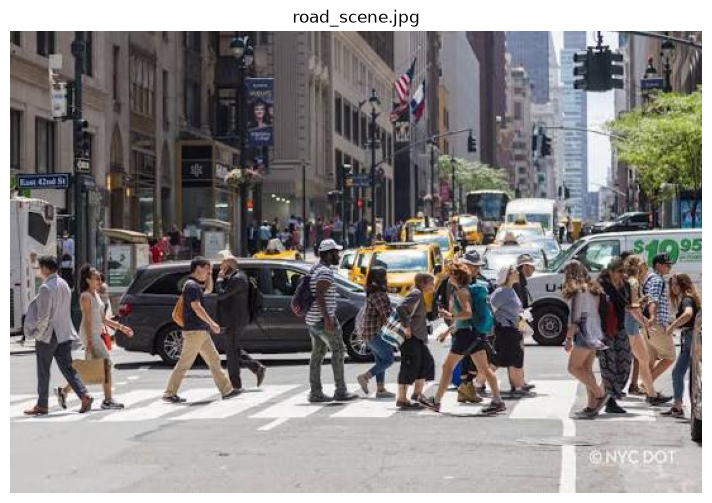

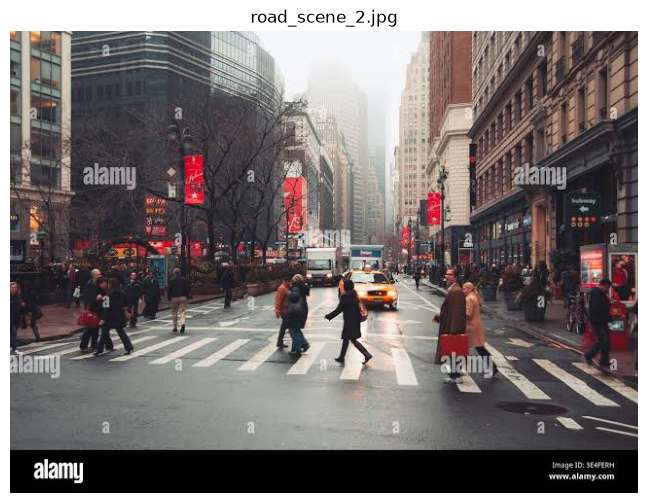

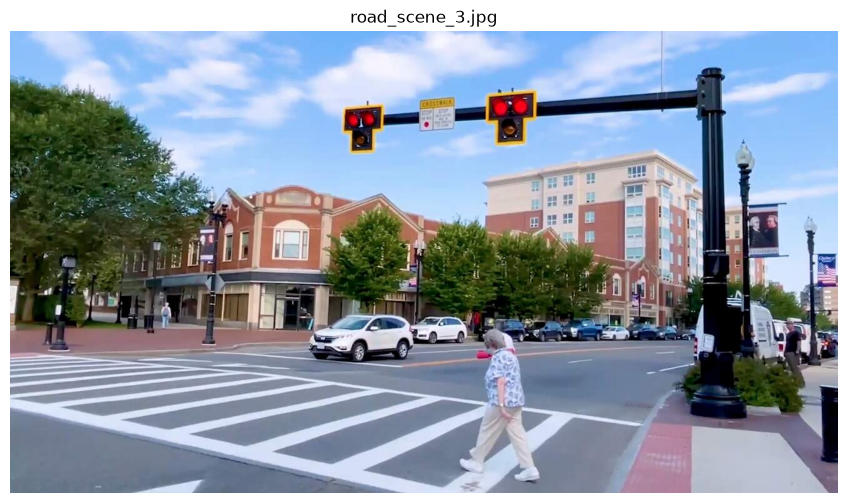

In [7]:
for image_name, image in images.items():

    plt.figure(figsize=(12, 6))

    plt.imshow(
        cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title(image_name)
    plt.axis("off")
    plt.show()

## 2. Load the CNN-Based Object Detection Model

The general YOLO model is used to detect common road objects. YOLO is a CNN-based object detection approach that predicts object classes and their bounding boxes from an input image.

For this prototype, the pretrained YOLO11n model is used for general road-object detection.

In [8]:
general_model = YOLO(
    str(BASE_DIR / "yolo11n.pt")
)

print("General YOLO model loaded successfully.")

General YOLO model loaded successfully.


In [9]:
ROAD_OBJECT_CLASSES = {
    "person",
    "car",
    "truck",
    "bus",
    "motorcycle",
    "bicycle"
}

print("Road object classes:")
for class_name in sorted(ROAD_OBJECT_CLASSES):
    print("-", class_name)

Road object classes:
- bicycle
- bus
- car
- motorcycle
- person
- truck


In [10]:
general_predictions = {}

for image_name, image in images.items():

    results = general_model.predict(
        source=image,
        conf=0.35,
        imgsz=640,
        verbose=False
    )

    result = results[0]

    predictions = []

    for box in result.boxes:

        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        class_name = general_model.names[class_id]

        if class_name not in ROAD_OBJECT_CLASSES:
            continue

        x1, y1, x2, y2 = box.xyxy[0].tolist()

        predictions.append({
            "object": class_name,
            "confidence": round(confidence, 3),
            "bounding_box": [
                round(x1),
                round(y1),
                round(x2),
                round(y2)
            ],
            "source": "general_yolo"
        })

    general_predictions[image_name] = predictions

    print(
        f"{image_name}: "
        f"{len(predictions)} road objects detected"
    )

road_scene.jpg: 18 road objects detected
road_scene_2.jpg: 10 road objects detected
road_scene_3.jpg: 11 road objects detected


In [11]:
for image_name, predictions in general_predictions.items():

    print("=" * 60)
    print(image_name)
    print("=" * 60)

    for index, prediction in enumerate(
        predictions,
        start=1
    ):

        print(
            f"{index}. "
            f"{prediction['object']} | "
            f"Confidence: {prediction['confidence']} | "
            f"Box: {prediction['bounding_box']}"
        )

road_scene.jpg
1. person | Confidence: 0.859 | Box: [120, 180, 179, 294]
2. person | Confidence: 0.821 | Box: [8, 176, 66, 305]
3. person | Confidence: 0.732 | Box: [435, 182, 474, 307]
4. person | Confidence: 0.706 | Box: [303, 189, 339, 300]
5. person | Confidence: 0.693 | Box: [377, 186, 417, 288]
6. person | Confidence: 0.689 | Box: [332, 179, 393, 304]
7. person | Confidence: 0.652 | Box: [54, 187, 96, 299]
8. person | Confidence: 0.648 | Box: [225, 165, 278, 294]
9. person | Confidence: 0.631 | Box: [517, 192, 547, 311]
10. person | Confidence: 0.592 | Box: [271, 183, 309, 292]
11. person | Confidence: 0.564 | Box: [158, 177, 203, 285]
12. truck | Confidence: 0.534 | Box: [0, 131, 37, 241]
13. car | Confidence: 0.51 | Box: [80, 179, 164, 264]
14. person | Confidence: 0.438 | Box: [463, 177, 500, 303]
15. car | Confidence: 0.438 | Box: [79, 179, 243, 261]
16. person | Confidence: 0.434 | Box: [232, 188, 272, 294]
17. bus | Confidence: 0.422 | Box: [359, 126, 395, 170]
18. bus | Co

## 3. Traffic Sign Detection

A specialized YOLO model is used to detect traffic signs that may not be included in the general road-object detector.

Because traffic signs can be small in road scenes, the prototype uses overlapping image tiles and an enlarged input during traffic-sign inference. This improves the ability to detect small signs while retaining their coordinates in the original image.

In [12]:
from huggingface_hub import HfApi, hf_hub_download

TRAFFIC_SIGN_REPO = "cvtechniques/TrafficSignDetection"

print("Finding traffic-sign model...")

api = HfApi()

files = api.list_repo_files(
    repo_id=TRAFFIC_SIGN_REPO
)

model_files = [
    file
    for file in files
    if file.lower().endswith(".pt")
]

best_models = [
    file
    for file in model_files
    if Path(file).name.lower() == "best.pt"
]

if best_models:
    traffic_sign_filename = best_models[0]
else:
    traffic_sign_filename = model_files[0]

print(
    "Traffic-sign model found:",
    traffic_sign_filename
)

Finding traffic-sign model...
Traffic-sign model found: best.pt


In [13]:
traffic_sign_path = hf_hub_download(
    repo_id=TRAFFIC_SIGN_REPO,
    filename=traffic_sign_filename
)

traffic_sign_model = YOLO(
    traffic_sign_path
)

print(
    "Traffic-sign model loaded successfully."
)

Traffic-sign model loaded successfully.


In [14]:
TRAFFIC_SIGN_CONFIDENCE = 0.20
TRAFFIC_SIGN_IMAGE_SIZE = 960

TILE_SIZE = 640
TILE_OVERLAP = 0.25


def calculate_iou(box_a, box_b):

    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    intersection_x1 = max(ax1, bx1)
    intersection_y1 = max(ay1, by1)

    intersection_x2 = min(ax2, bx2)
    intersection_y2 = min(ay2, by2)

    intersection_width = max(
        0,
        intersection_x2 - intersection_x1
    )

    intersection_height = max(
        0,
        intersection_y2 - intersection_y1
    )

    intersection_area = (
        intersection_width *
        intersection_height
    )

    area_a = (
        max(0, ax2 - ax1) *
        max(0, ay2 - ay1)
    )

    area_b = (
        max(0, bx2 - bx1) *
        max(0, by2 - by1)
    )

    union_area = (
        area_a +
        area_b -
        intersection_area
    )

    if union_area == 0:
        return 0.0

    return intersection_area / union_area


def remove_duplicate_signs(
    predictions,
    iou_threshold=0.45
):

    if not predictions:
        return []

    final_predictions = []

    classes = set(
        prediction["object"]
        for prediction in predictions
    )

    for class_name in classes:

        class_predictions = [
            prediction
            for prediction in predictions
            if prediction["object"] == class_name
        ]

        class_predictions.sort(
            key=lambda item: item["confidence"],
            reverse=True
        )

        kept = []

        while class_predictions:

            current = class_predictions.pop(0)

            kept.append(current)

            remaining = []

            for candidate in class_predictions:

                iou = calculate_iou(
                    current["bounding_box"],
                    candidate["bounding_box"]
                )

                if iou < iou_threshold:
                    remaining.append(candidate)

            class_predictions = remaining

        final_predictions.extend(kept)

    final_predictions.sort(
        key=lambda item: item["confidence"],
        reverse=True
    )

    return final_predictions

In [15]:
traffic_sign_predictions = {}

for image_name, image in images.items():

    print("=" * 60)
    print(
        f"Processing traffic signs: {image_name}"
    )
    print("=" * 60)

    image_height, image_width = image.shape[:2]

    predictions = []

    stride = int(
        TILE_SIZE *
        (1 - TILE_OVERLAP)
    )

    y_positions = list(
        range(
            0,
            max(
                1,
                image_height - TILE_SIZE + 1
            ),
            stride
        )
    )

    x_positions = list(
        range(
            0,
            max(
                1,
                image_width - TILE_SIZE + 1
            ),
            stride
        )
    )

    if image_height > TILE_SIZE:

        final_y = image_height - TILE_SIZE

        if final_y not in y_positions:
            y_positions.append(final_y)

    if image_width > TILE_SIZE:

        final_x = image_width - TILE_SIZE

        if final_x not in x_positions:
            x_positions.append(final_x)

    if image_height <= TILE_SIZE:
        y_positions = [0]

    if image_width <= TILE_SIZE:
        x_positions = [0]

    for y in y_positions:

        for x in x_positions:

            y2 = min(
                y + TILE_SIZE,
                image_height
            )

            x2 = min(
                x + TILE_SIZE,
                image_width
            )

            tile = image[
                y:y2,
                x:x2
            ]

            enlarged_tile = cv2.resize(
                tile,
                None,
                fx=1.5,
                fy=1.5,
                interpolation=cv2.INTER_CUBIC
            )

            results = traffic_sign_model.predict(
                source=enlarged_tile,
                conf=TRAFFIC_SIGN_CONFIDENCE,
                imgsz=TRAFFIC_SIGN_IMAGE_SIZE,
                verbose=False
            )

            result = results[0]

            for box in result.boxes:

                class_id = int(box.cls[0])

                confidence = float(
                    box.conf[0]
                )

                class_name = (
                    traffic_sign_model.names[
                        class_id
                    ]
                )

                tx1, ty1, tx2, ty2 = (
                    box.xyxy[0].tolist()
                )

                scale = 1.5

                tx1 /= scale
                ty1 /= scale
                tx2 /= scale
                ty2 /= scale

                full_x1 = x + tx1
                full_y1 = y + ty1
                full_x2 = x + tx2
                full_y2 = y + ty2

                full_x1 = max(
                    0,
                    min(
                        full_x1,
                        image_width
                    )
                )

                full_y1 = max(
                    0,
                    min(
                        full_y1,
                        image_height
                    )
                )

                full_x2 = max(
                    0,
                    min(
                        full_x2,
                        image_width
                    )
                )

                full_y2 = max(
                    0,
                    min(
                        full_y2,
                        image_height
                    )
                )

                predictions.append({
                    "object": class_name,
                    "confidence": round(
                        confidence,
                        3
                    ),
                    "bounding_box": [
                        round(full_x1),
                        round(full_y1),
                        round(full_x2),
                        round(full_y2)
                    ],
                    "source": "traffic_sign_yolo"
                })

    predictions = remove_duplicate_signs(
        predictions
    )

    traffic_sign_predictions[
        image_name
    ] = predictions

    print(
        f"Traffic signs detected: "
        f"{len(predictions)}"
    )

Processing traffic signs: road_scene.jpg
Traffic signs detected: 1
Processing traffic signs: road_scene_2.jpg
Traffic signs detected: 0
Processing traffic signs: road_scene_3.jpg
Traffic signs detected: 0


In [16]:
for image_name, predictions in traffic_sign_predictions.items():

    print("=" * 60)
    print(image_name)
    print("=" * 60)

    if not predictions:

        print("No traffic signs detected.")

        continue

    for index, prediction in enumerate(
        predictions,
        start=1
    ):

        print(
            f"{index}. "
            f"{prediction['object']} | "
            f"Confidence: "
            f"{prediction['confidence']} | "
            f"Box: "
            f"{prediction['bounding_box']}"
        )

road_scene.jpg
1. stop | Confidence: 0.628 | Box: [416, 214, 439, 243]
road_scene_2.jpg
No traffic signs detected.
road_scene_3.jpg
No traffic signs detected.


In [17]:
combined_predictions = {}

for image_name in IMAGE_FILES:

    general_results = general_predictions.get(
        image_name,
        []
    )

    sign_results = traffic_sign_predictions.get(
        image_name,
        []
    )

    combined = (
        general_results +
        sign_results
    )

    combined_predictions[
        image_name
    ] = combined

    print("=" * 60)
    print(image_name)
    print("=" * 60)

    print(
        "General road objects:",
        len(general_results)
    )

    print(
        "Traffic signs:",
        len(sign_results)
    )

    print(
        "Total structured predictions:",
        len(combined)
    )

road_scene.jpg
General road objects: 18
Traffic signs: 1
Total structured predictions: 19
road_scene_2.jpg
General road objects: 10
Traffic signs: 0
Total structured predictions: 10
road_scene_3.jpg
General road objects: 11
Traffic signs: 0
Total structured predictions: 11


In [18]:
for image_name, predictions in combined_predictions.items():

    print("\n" + "=" * 70)
    print(image_name)
    print("=" * 70)

    for index, prediction in enumerate(
        predictions,
        start=1
    ):

        print(
            f"{index}. "
            f"{prediction['object']} | "
            f"Confidence: {prediction['confidence']} | "
            f"Bounding Box: {prediction['bounding_box']} | "
            f"Source: {prediction['source']}"
        )


road_scene.jpg
1. person | Confidence: 0.859 | Bounding Box: [120, 180, 179, 294] | Source: general_yolo
2. person | Confidence: 0.821 | Bounding Box: [8, 176, 66, 305] | Source: general_yolo
3. person | Confidence: 0.732 | Bounding Box: [435, 182, 474, 307] | Source: general_yolo
4. person | Confidence: 0.706 | Bounding Box: [303, 189, 339, 300] | Source: general_yolo
5. person | Confidence: 0.693 | Bounding Box: [377, 186, 417, 288] | Source: general_yolo
6. person | Confidence: 0.689 | Bounding Box: [332, 179, 393, 304] | Source: general_yolo
7. person | Confidence: 0.652 | Bounding Box: [54, 187, 96, 299] | Source: general_yolo
8. person | Confidence: 0.648 | Bounding Box: [225, 165, 278, 294] | Source: general_yolo
9. person | Confidence: 0.631 | Bounding Box: [517, 192, 547, 311] | Source: general_yolo
10. person | Confidence: 0.592 | Bounding Box: [271, 183, 309, 292] | Source: general_yolo
11. person | Confidence: 0.564 | Bounding Box: [158, 177, 203, 285] | Source: general_yo

In [19]:
def draw_combined_predictions(
    image,
    predictions
):

    output = image.copy()

    for prediction in predictions:

        x1, y1, x2, y2 = prediction[
            "bounding_box"
        ]

        object_name = prediction[
            "object"
        ]

        confidence = prediction[
            "confidence"
        ]

        source = prediction[
            "source"
        ]

        if source == "traffic_sign_yolo":

            box_color = (
                0,
                0,
                255
            )

        else:

            box_color = (
                0,
                255,
                0
            )

        label = (
            f"{object_name} "
            f"{confidence:.2f}"
        )

        cv2.rectangle(
            output,
            (x1, y1),
            (x2, y2),
            box_color,
            2
        )

        label_y = max(
            y1 - 8,
            20
        )

        cv2.putText(
            output,
            label,
            (x1, label_y),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            box_color,
            2
        )

    return output

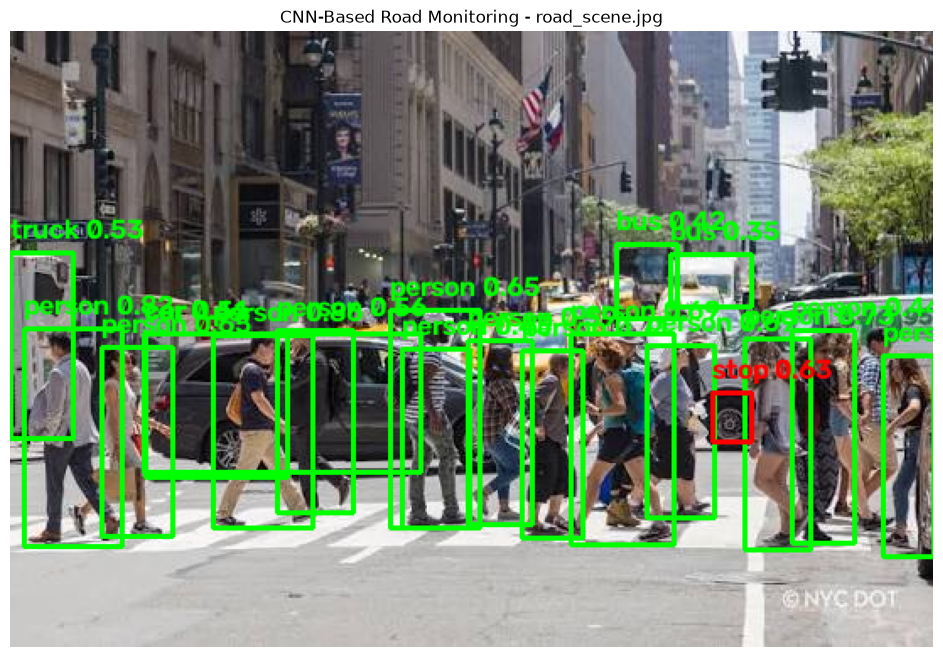

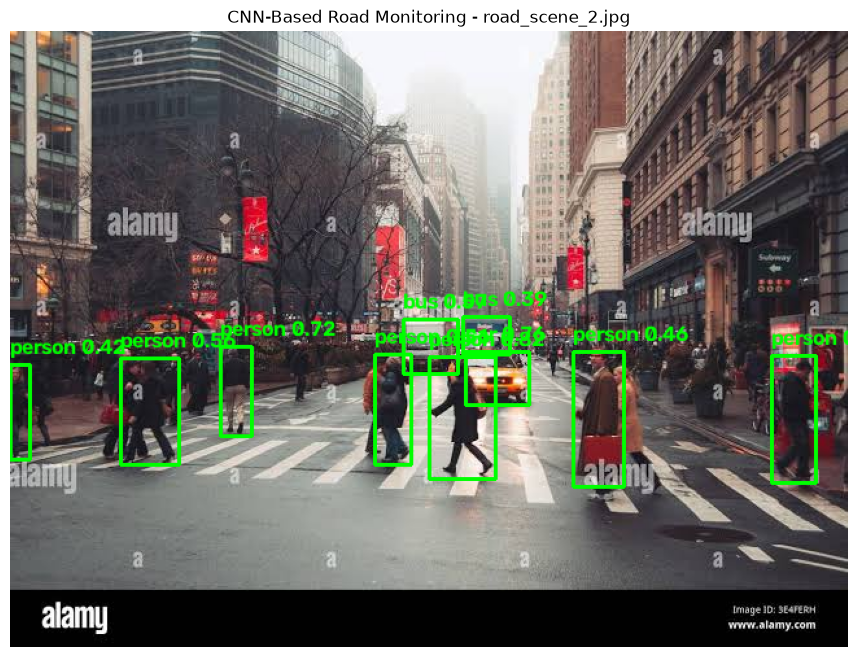

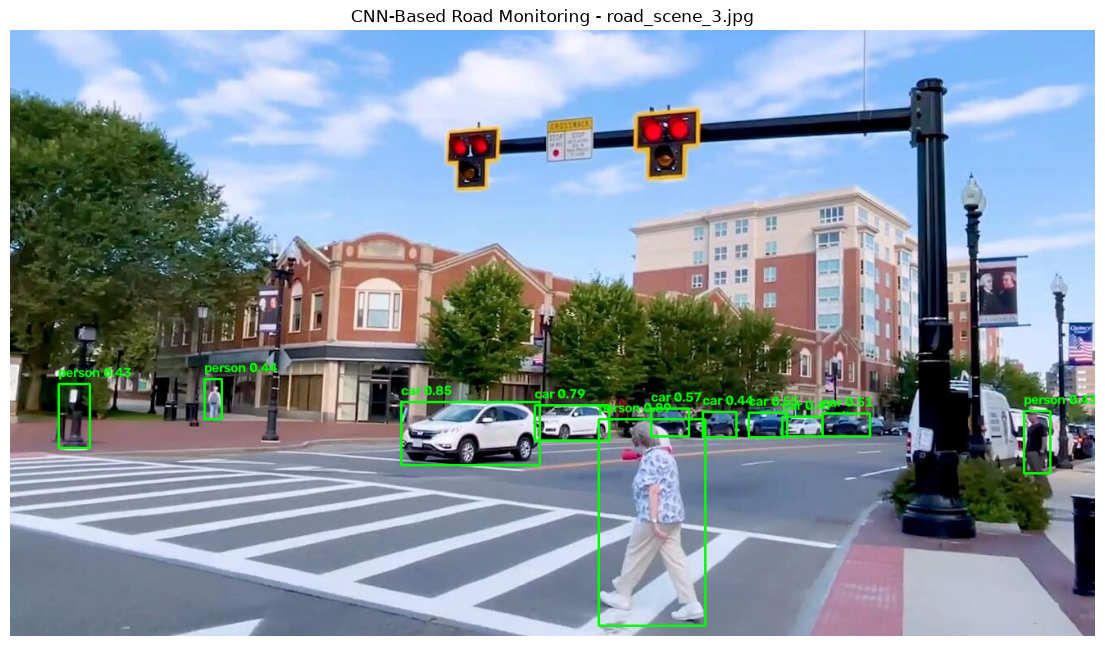

In [20]:
final_images = {}

for image_name, predictions in combined_predictions.items():

    image = images[image_name]

    annotated_image = draw_combined_predictions(
        image,
        predictions
    )

    final_images[
        image_name
    ] = annotated_image

    plt.figure(
        figsize=(14, 8)
    )

    plt.imshow(
        cv2.cvtColor(
            annotated_image,
            cv2.COLOR_BGR2RGB
        )
    )

    plt.title(
        f"CNN-Based Road Monitoring - {image_name}"
    )

    plt.axis("off")

    plt.show()

In [21]:
for image_name, predictions in combined_predictions.items():

    image_stem = Path(
        image_name
    ).stem

    output_image_path = (
        RESULTS_DIR /
        f"{image_stem}_final_detected.jpg"
    )

    output_json_path = (
        RESULTS_DIR /
        f"{image_stem}_predictions.json"
    )

    cv2.imwrite(
        str(output_image_path),
        final_images[image_name]
    )

    with open(
        output_json_path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            predictions,
            file,
            indent=4
        )

    print(
        f"{image_name} saved successfully."
    )

    print(
        "Image:",
        output_image_path
    )

    print(
        "JSON:",
        output_json_path
    )

road_scene.jpg saved successfully.
Image: C:\Users\Rejeena Agastian\Desktop\road-monitoring-cnn\results\road_scene_final_detected.jpg
JSON: C:\Users\Rejeena Agastian\Desktop\road-monitoring-cnn\results\road_scene_predictions.json
road_scene_2.jpg saved successfully.
Image: C:\Users\Rejeena Agastian\Desktop\road-monitoring-cnn\results\road_scene_2_final_detected.jpg
JSON: C:\Users\Rejeena Agastian\Desktop\road-monitoring-cnn\results\road_scene_2_predictions.json
road_scene_3.jpg saved successfully.
Image: C:\Users\Rejeena Agastian\Desktop\road-monitoring-cnn\results\road_scene_3_final_detected.jpg
JSON: C:\Users\Rejeena Agastian\Desktop\road-monitoring-cnn\results\road_scene_3_predictions.json


## 4. Results

The CNN-based road-monitoring prototype successfully detected multiple road objects from the test images.

The general YOLO model identified objects such as pedestrians, cars, buses, and trucks. A specialized traffic-sign YOLO model was additionally used to identify traffic signs.

For the first road scene, the system detected 18 general road objects and 1 traffic sign, producing 19 structured predictions in total.

Each prediction contains:
- Object class
- Confidence score
- Bounding-box coordinates
- Detection model source

The final predictions are visualized using bounding boxes and are also stored in JSON format.

## 5. Limitations

Traffic-sign detection depends on the size, visibility, distance, and quality of signs in the input image. Small or partially visible signs may not be detected.

In the tested images, the specialized model detected a stop sign in the first road scene, while no traffic signs were detected in the other two scenes.

The prototype is intended for academic demonstration and is not a safety-critical road-monitoring system.

## 6. Conclusion

A CNN-based road-monitoring prototype was developed using YOLO object-detection models. The system processes road images and produces multiple structured predictions containing object labels, confidence scores, bounding boxes, and model sources.

The prototype demonstrates detection of common road objects such as cars and pedestrians along with specialized traffic-sign detection. The results are visualized using bounding boxes and stored in JSON format for structured analysis.